# Polimerização do pirrol: estatística de Flory-Schulz + termodinâmica de Flory-Huggins

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from IPython.display import display
import json, warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

## 1. Constantes, dados de entrada e fontes

| Símbolo | Valor |
|---|---|
| $R$ | 8,314462618 J mol$^{-1}$ K$^{-1}$ |
| $T$ | 298,15 K |
| $\delta_D,\delta_P,\delta_H$ e $V$ do pirrol | 19,2 / 7,4 / 6,7 MPa$^{1/2}$; 69,2 cm³/mol |
| $\delta_D,\delta_P,\delta_H$ e $V$ da acetonitrila | 15,3 / 18,0 / 6,1; 52,6 cm³/mol |
| $\delta_D,\delta_P,\delta_H$ e $V$ da água | 15,5 / 16,0 / 42,3; 18,0 cm³/mol |
| $\alpha$ (fator da equação de $\chi$) | 0,6 |
| $M$ da unidade repetida do PPy (C$_4$H$_3$N) | 65,07 g/mol |
| $\rho_{PPy}$ | 1,60 g/cm³ |
| $\delta_D,\delta_P,\delta_H$ do PPy | Calculados na Seção 1b |
| Solubilidade do pirrol em água | 45–60 g/L a 25 °C (≈0,67–0,9 mol/L) |
| $\rho_{pirrol}$, $M_{pirrol}$ | 0,967 g/mL; 67,09 g/mol |
| $c_0$ (pirrol no meio de síntese) | ≈0,051 mol/L |
| Meio e oxidante | Água ultrapura; APS 0,063 mol/L (razão APS:pirrol ≈1,23–1,27); 2 h, temperatura ambiente (usado 25 °C) |

Obs.: Todas as referências das constantes constam no arquivo do texto escrito

In [18]:
R = 8.314462618 # J/(mol K)
T = 298.15 # K

# Hansen Handbook (MPa^0.5, cm3/mol)
pirrol = dict(dD=19.2, dP=7.4, dH=6.7, V=69.2)
solventes = {
    'acetonitrila': dict(dD=15.3, dP=18.0, dH=6.1,  V=52.6), # Tabela 15.4A, pag 282
    'agua':         dict(dD=15.5, dP=16.0, dH=42.3, V=18.0), # Tabela 15.4A, pag 282
}
alpha = 0.6 # Lindvig et al. 2002

# Ppy
M_rep   = 4*12.011 + 3*1.008 + 14.007 # g/mol (C4H3N)
rho_PPy = 1.6 # g/cm3 (tirei do chemical book)
V_rep   = M_rep / rho_PPy # cm3/mol
print(f'M_rep = {M_rep:.2f} g/mol ; V_rep = {V_rep:.1f} cm3/mol')


# Baseado na síntese de LA
M_pirrol, rho_pirrol = 67.09, 0.967 # g/mol, g/mL
M_APS = 228.18 # g/mol
V_total_L = 0.050 
n_pir_dens = 178.6e-3*rho_pirrol/M_pirrol # mol
n_pir_14M  = 178.6e-6*14 # mol
n_APS = 0.722/M_APS
c0_receita = n_pir_dens/V_total_L # mol/L
print(f'pirrol: {n_pir_dens*1e3:.2f} mmol (densidade) / {n_pir_14M*1e3:.2f} mmol (14 M) -> c0 = {c0_receita:.4f} mol/L')
print(f'APS: {n_APS*1e3:.2f} mmol -> {n_APS/V_total_L:.4f} mol/L ; razao APS:pirrol = {n_APS/n_pir_dens:.2f} (densidade) / {n_APS/n_pir_14M:.2f} (14 M)')
c0_lista = [c0_receita/2, c0_receita, 2*c0_receita] 

M_rep = 65.08 g/mol ; V_rep = 40.7 cm3/mol
pirrol: 2.57 mmol (densidade) / 2.50 mmol (14 M) -> c0 = 0.0515 mol/L
APS: 3.16 mmol -> 0.0633 mol/L ; razao APS:pirrol = 1.23 (densidade) / 1.27 (14 M)


## 1b. Parâmetros de Hansen do PPy caluladas pelo método de Hoftyzer–Van Krevelen

Se soma as contribuições extensivas de cada grupo (não os $\delta$): $F_{di}$ (dispersão), $F_{pi}$ (polar) e $E_{hi}$ (ligação de H). Depois se divide pelo volume molar $V$:

$$\delta_D=\frac{\sum F_{di}}{V},\qquad \delta_P=\frac{\sqrt{\sum F_{pi}^2}}{V},\qquad \delta_H=\sqrt{\frac{\sum E_{hi}}{V}} .$$

Grupos usados (Tabela 7.10 do livro): =CH–, =C<, –NH– e Ring.

Unidade repetida do PPy: $2\,{=}CH–$, $2\,{=}C{<}$, $1\,{–}NH{–}$ e o anel, somados diretamente e divididos por $V_{rep}=M_{rep}/\rho_{PPy}$.

Regra de conferência da atribuição de grupos: cada grupo da Tabela 7.10 já inclui seus hidrogênios. A soma dos grupos tem de reproduzir a fórmula da unidade repetida, $\text{C}_4\text{H}_3\text{N}$ (65,07 g/mol): $2\,{=}CH–+2\,{=}C{<}+1\,{–}NH–$ dá C$_4$H$_3$N. Já $4\,{=}C{<}+1\,{>}N–$ daria C$_4$N, sem hidrogênio (isso seria um anel totalmente substituído e reticulado, e o $>N–$ da tabela é amina terciária, com $F_p=800$ e $E_h=5000$, valores muito diferentes do $–NH–$).

Obs.: foi apliado esse método ao próprio pirrol e comparamos com o Handbook para avaliar a confiabilidade do cálculo.

In [19]:
GRUPOS = {'=CH-': (200, 0, 0), '=C<': (70, 0, 0), '-NH-': (160, 210, 3100), 'Ring': (190, 0, 0)}

def hvk(grupos, V, sim=1.0):
    Fd  = sum(n*GRUPOS[g][0] for g,n in grupos.items())
    Fp2 = sum(n*GRUPOS[g][1]**2 for g,n in grupos.items())*sim
    Eh  = sum(n*GRUPOS[g][2] for g,n in grupos.items())
    return dict(dD=Fd/V, dP=np.sqrt(Fp2)/V, dH=np.sqrt(Eh/V))

# teste no pirrol
Vpir = pirrol['V']
teste = hvk({'=CH-':4, '-NH-':1, 'Ring':1}, Vpir)
print('PIRROL (Handbook): dD=%.1f  dP=%.1f  dH=%.1f' % (pirrol['dD'], pirrol['dP'], pirrol['dH']))
print('PIRROL (calculado Van Krevelen) : dD=%.1f  dP=%.1f  dH=%.1f' % (teste['dD'], teste['dP'], teste['dH']))

# Ppy
ppy_grupos = {'=CH-':2, '=C<':2, '-NH-':1, 'Ring':1}
ppy_hansen = {'A': hvk(ppy_grupos, V_rep)}

tab_ppy = pd.DataFrame(ppy_hansen).T
tab_ppy['soma(d^2)^0.5'] = np.sqrt((tab_ppy**2).sum(axis=1))
print(f'PPy, unidade repetida: V_rep = {V_rep:.1f} cm3/mol (rho_PPy = {rho_PPy} g/cm3)')
display(tab_ppy.round(2))

PIRROL (Handbook): dD=19.2  dP=7.4  dH=6.7
PIRROL (calculado Van Krevelen) : dD=16.6  dP=3.0  dH=6.7
PPy, unidade repetida: V_rep = 40.7 cm3/mol (rho_PPy = 1.6 g/cm3)


,dD,dP,dH,soma(d^2)^0.5
A,21.88,5.16,8.73,24.12


Obs.: o método reproduz delta_H, subestima delta_D e delta_P (o dipolo do anel heteroaromatico nao tem grupo na tabela)

## 2. Estatística de Flory (1936): distribuição mais provável

Cada monômero de pirrol tem dois grupos reativos (posições $\alpha$, 2 e 5). Seja $p$ a probabilidade de um grupo qualquer já ter reagido, uma molécula com exatamente $x$ unidades tem $x-1$ ligações formadas (probabilidade $p^{\,x-1}$) e duas pontas livres, e a probabilidade de a ponta seguinte não ter reagido é $(1-p)$. Logo, a fração (em número) de moléculas com $x$ unidades é dada por:

$$P(x)=(1-p)\,p^{\,x-1}.$$

A fração em massa é $w(x)=x\,(1-p)^2\,p^{\,x-1}$ e os momentos são

$$X_n=\frac{1}{1-p},\qquad X_w=\frac{1+p}{1-p},\qquad X_z=\frac{1+4p+p^2}{(1+p)(1-p)},\qquad \frac{X_w}{X_n}=1+p .$$

Resultados úteis para o pirrol: a fração em massa de monômero residual é $w(1)=(1-p)^2$, e $X_n=1/(1-p)$ (equação de Carothers).

Hipóteses de Flory (1936): monômero bifuncional com reatividade de um grupo independente do tamanho da cadeia. A é reação aleatória e irreversível, sem ciclização nem ramificação. O pirrol satisfaz a primeira, entretanto oligômeros oxidam mais facilmente que monômeros (não satisfaz o segundo ponto). Mecanismo da polimerização oxidativa do pirrol é debatido em (Sadki et al., *Chem. Soc. Rev.* 2000). Por isso $p$ é varrido, não fixado.

,p,Xn,Xw,Xz,PDI=Xw/Xn,monomero residual (massa)=(1-p)^2
0,0.500,2.0,3.0,4.3333,1.500,0.2500
1,0.900,10.0,19.0,28.4737,1.900,0.0100
2,0.950,20.0,39.0,58.4872,1.950,0.0025
3,0.990,100.0,199.0,298.4975,1.990,0.0001
4,0.995,200.0,399.0,598.4987,1.995,0.0000
5,0.999,1000.0,1999.0,2998.4997,1.999,0.0000


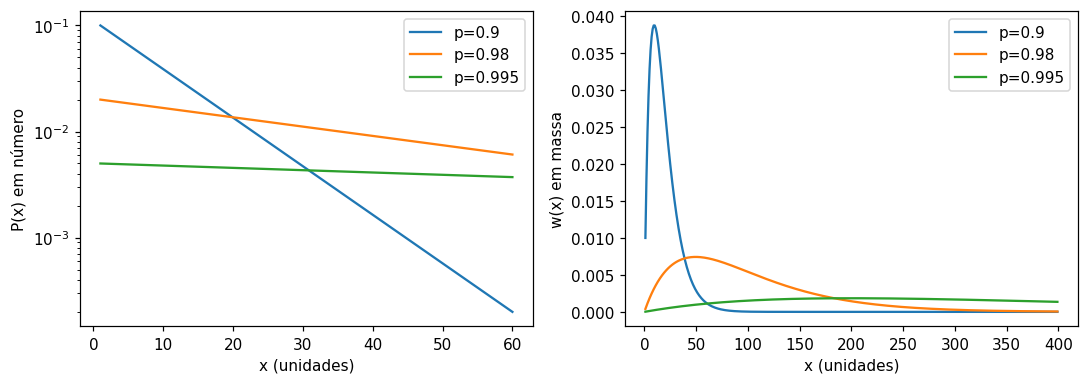

In [20]:
def Xn(p): return 1/(1-p)
def Xw(p): return (1+p)/(1-p)
def Xz(p): return (1+4*p+p**2)/((1+p)*(1-p))
def P_num(x,p): return (1-p)*p**(x-1) # fracao em numero
def w_mass(x,p): return x*(1-p)**2*p**(x-1) # fracao em massa

ps = [0.5, 0.9, 0.95, 0.99, 0.995, 0.999]
tab = pd.DataFrame({'p':ps,
                    'Xn':[Xn(p) for p in ps],
                    'Xw':[Xw(p) for p in ps],
                    'Xz':[Xz(p) for p in ps],
                    'PDI=Xw/Xn':[Xw(p)/Xn(p) for p in ps],
                    'monomero residual (massa)=(1-p)^2':[(1-p)**2 for p in ps]})
display(tab.round(4))

x = np.arange(1,400)
fig,ax = plt.subplots(1,2,figsize=(10,3.6))
for p in [0.9,0.98,0.995]:
    ax[0].semilogy(x[:60],P_num(x[:60],p),label=f'p={p}')
    ax[1].plot(x,w_mass(x,p),label=f'p={p}')
ax[0].set_xlabel('x (unidades)'); ax[0].set_ylabel('P(x) em número'); ax[0].legend()
ax[1].set_xlabel('x (unidades)'); ax[1].set_ylabel('w(x) em massa'); ax[1].legend()
plt.tight_layout(); plt.show()

Definição das variáveis:
- p: fração dos grupos reativos que já reagiram, descreve em que ponto da reação estamos
- X_n: grau de polimerização médio em número (tamanho do "indivíduo médio")
- X_w: grau de polimerização médio em massa
- X_z: cauda da distribuição
- PDI: índice polidispersividade
- monômero residual: fração da massa total do pirrol que ainda é livre (sobrou sem reagir)

## 3. Flory-Huggins (Flory 1942, 1944)

1. Rede (Flory 1942): sítios do tamanho do solvente; espécie $i$ com $N_i$ sítios e fração de volume $\phi_i$; solvente $N_0=1$.
2. Energia livre de mistura por sítio para solvente + várias espécies de cadeia (Flory 1944; Scott & Magat 1945), com um único $\chi$ para a série homóloga:

$$\frac{\Delta G_{mix}}{kT}=\phi_0\ln\phi_0+\sum_i\frac{\phi_i}{N_i}\ln\phi_i+\chi\,\phi_0(1-\phi_0).$$

3. Estabilidade: a Hessiana em $(\phi_1,\dots,\phi_n)$ é $\mathbf D + c\,\mathbf 1\mathbf 1^T$, com $D_{ii}=1/(N_i\phi_i)$ e $c=1/\phi_0-2\chi$. Seu determinante se anula quando $1+c\sum_i N_i\phi_i=0$, o que dá a espinodal

$$2\chi_s=\frac{1}{1-\phi}+\frac{1}{\phi\,N_w},\qquad N_w=r\,X_w .$$

   Só o peso-médio $N_w$ importa.
4. Ponto crítico: anulando também a terceira derivada ao longo da direção instável (que envolve $N_z=rX_z$):

$$\phi_c=\frac{1}{1+N_w/\sqrt{N_z}},\qquad \chi_c=\chi_s(\phi_c).$$

   Para cadeia monodispersa ($N_w=N_z=N$) recupera-se $\chi_c=\tfrac12(1+1/\sqrt N)^2$.

In [21]:
def chi_spinodal(phi, Nw):
    return 0.5*(1/(1-phi) + 1/(phi*Nw))

def ponto_critico(Nw, Nz):
    phic = 1/(1 + Nw/np.sqrt(Nz))
    return phic, chi_spinodal(phic, Nw)

def det_hessiana_rel(phi, p, r, chi, xmax=8000):
 # det(H)/det(D) = 1 + c * sum(N_i phi_i)   (H = D + c 1 1^T)
    x = np.arange(1, xmax+1); N = r*x
    w = w_mass(x,p); w = w/w.sum()
    phis = phi*w
    c = 1/(1-phi) - 2*chi
    return 1 + c*np.sum(N*phis)

# teste: p=0.99, r=0.884, phi=0.007
p, r, phi = 0.99, 0.884, 0.007
Nw, Nz = r*Xw(p), r*Xz(p)
chi_s = chi_spinodal(phi, Nw)
raiz_num = brentq(lambda c: det_hessiana_rel(phi,p,r,c), 0.2, 3)
print(f'espinodal analitica = {chi_s:.6f} | raiz numerica da Hessiana = {raiz_num:.6f}')
print('ponto critico (phi_c, chi_c) =', ponto_critico(Nw, Nz))

espinodal analitica = 0.909563 | raiz numerica da Hessiana = 0.909563
ponto critico (phi_c, chi_c) = (np.float64(0.0845343440791738), np.float64(0.5797927481080787))


## 4. Parâmetro $\chi$ (Hansen)

O que $\chi$ mede: na rede de Flory-Huggins, trocar um contato polímero–polímero e um solvente–solvente por dois contatos polímero–solvente custa $\Delta w = w_{12}-\tfrac12(w_{11}+w_{22})$. O parâmetro é
$$\chi=\frac{z\,\Delta w}{kT},$$
isto é, a energia (em unidades de $kT$) por segmento associada a colocar um segmento de polímero no meio do solvente. Não é propriedade só do polímero nem do tamanho da cadeia: é uma propriedade do par polímero–solvente e da temperatura, e seu valor depende do volume do segmento escolhido (volume do solvente). Para cadeias longas, $\chi<0{,}5$ é bom solvente, $\chi=0{,}5$ é condição $\theta$ e $\chi>0{,}5$ é solvente pobre. O $\chi$ de Hansen usado aqui só captura a parte entálpica (descasamento de energia coesiva, por isso é sempre $\geq0$) e não captura interações específicas, como ligação de H direcional entre polímero e solvente.

$$\chi_{ij}=\alpha\,\frac{V_s}{RT}\Big[(\Delta\delta_D)^2+0{,}25(\Delta\delta_P)^2+0{,}25(\Delta\delta_H)^2\Big],\qquad \alpha=0{,}6,$$

com $V_s$ o volume molar do solvente (volume do sítio).

Teste método: o pirrol é só parcialmente miscível com água (45–60 g/L) e miscível com acetonitrila. Calculamos $\chi_{pirrol-água}$ por Hansen e, com a binodal de Flory-Huggins binária, prevemos a solubilidade. Se o método for razoável, deve cair na ordem de grandeza do dado

In [22]:
def chi_hansen(d1, d2, Vs, alpha=0.6, T=T):
    t = (d1['dD']-d2['dD'])**2 + 0.25*(d1['dP']-d2['dP'])**2 + 0.25*(d1['dH']-d2['dH'])**2 # MPa
    return alpha*Vs*t/(R*T) # cm3/mol * MPa = J/mol

linhas = []
for s,v in solventes.items():
    linhas.append(dict(solvente=s, par='pirrol', chi=chi_hansen(pirrol, v, v['V'], alpha)))
    for k,d in ppy_hansen.items():
        linhas.append(dict(solvente=s, par=f'PPy ({k})', chi=chi_hansen(d, v, v['V'], alpha)))
tab_chi = pd.DataFrame(linhas).pivot(index='par', columns='solvente', values='chi')
display(tab_chi.round(3))

# binodal binaria FH: solvente (N=1) + soluto de N sitios
def mu1(f,N,c): return np.log(1-f) + f*(1-1/N) + c*f**2
def mu2(f,N,c): return np.log(f) + (1-f)*(1-N) + N*c*(1-f)**2
def binodal_binaria(N, c):
    h = lambda f: 1/(1-f) + 1/(N*f) - 2*c
    fc = 1/(1+np.sqrt(N))
    a_s = brentq(h, 1e-9, fc); b_s = brentq(h, fc, 1-1e-9)
    def phib(fa):
        m = mu1(fa,N,c); return brentq(lambda fb: mu1(fb,N,c)-m, b_s, 1-1e-12)
    def Rr(fa):
        try: return mu2(fa,N,c)-mu2(phib(fa),N,c)
        except Exception: return np.nan
    g = np.linspace(a_s*1e-3, a_s*0.9999, 2500); v = np.array([Rr(f) for f in g])
    for i in range(len(g)-1):
        if np.isfinite(v[i]) and np.isfinite(v[i+1]) and v[i]*v[i+1] < 0:
            fa = brentq(Rr, g[i], g[i+1]); return fa, phib(fa)
    return None

rho_pir = 0.967 # g/mL
Nmon = pirrol['V']/solventes['agua']['V']
chi_pw = chi_hansen(pirrol, solventes['agua'], solventes['agua']['V'], alpha)
chi_crit_mon = 0.5*(1+1/np.sqrt(Nmon))**2
print(f'pirrol em agua: N={Nmon:.2f} sitios, chi(Hansen)={chi_pw:.3f}, chi_critico={chi_crit_mon:.3f}')
b = binodal_binaria(Nmon, chi_pw)
if b:
    print(f'solubilidade prevista (ramo diluido): phi={b[0]:.4f} -> {b[0]*rho_pir*1000:.1f} g/L = {b[0]/pirrol["V"]*1000:.2f} mol/L')
print('dado de catalogo [B]: 45-60 g/L (~0,67-0,9 mol/L)')

# alpha que reproduz o dado
for g_L in (45, 60):
    ft = g_L/rho_pir/1000
    f = lambda c: (binodal_binaria(Nmon,c)[0] if binodal_binaria(Nmon,c) else np.nan) - ft
    try:
        c_fit = brentq(f, 1.2, 1.7)
        print(f'{g_L} g/L exigiria chi={c_fit:.3f}  ->  alpha equivalente = {c_fit/chi_pw*alpha:.2f}')
    except Exception as e:
        print('ajuste falhou', e)

chi_pm = chi_hansen(pirrol, solventes['acetonitrila'], solventes['acetonitrila']['V'], alpha)
Nm2 = pirrol['V']/solventes['acetonitrila']['V']
print(f'pirrol em acetonitrila: chi={chi_pm:.3f} < chi_critico={0.5*(1+1/np.sqrt(Nm2))**2:.3f}')

solvente,acetonitrila,agua
par,,
PPy (A),1.098,1.533
pirrol,0.552,1.521


pirrol em agua: N=3.84 sitios, chi(Hansen)=1.521, chi_critico=1.140
solubilidade prevista (ramo diluido): phi=0.0381 -> 36.8 g/L = 0.55 mol/L
dado de catalogo [B]: 45-60 g/L (~0,67-0,9 mol/L)
45 g/L exigiria chi=1.471  ->  alpha equivalente = 0.58
60 g/L exigiria chi=1.403  ->  alpha equivalente = 0.55
pirrol em acetonitrila: chi=0.552 < chi_critico=1.752


## 5. Quando a mistura de oligômeros deixa de ser estável? (Flory 1944)

Ponto de operação: o pirrol entra a concentração $c_0$ e sua fração de volume é $\phi=c_0V_{pirrol}/1000$. Mantemos $\phi$ constante enquanto $p$ cresce (volume conservado). A mistura é: solvente + todas as espécies de $x=1,2,3,\dots$ (o monômero é a espécie $x=1$), com a distribuição de Flory.

Duas condições (para $\chi$ dado, vemos em que $p$ elas são atingidas):

* Espinodal (limite de estabilidade): $N_w^*=\dfrac{1}{\phi\,[\,2\chi-1/(1-\phi)\,]}$, depois $X_w^*=N_w^*/r$ e $p^*=(X_w^*-1)/(X_w^*+1)$.
* Ponto de névoa (início real da separação de fases): vem do equilíbrio de Flory (1944), onde a espécie $x$ se reparte entre as fases $'$ e $''$ como $\ln(\phi_x'/\phi_x'')=\sigma N_x$ (o mesmo $\sigma$ para todas, o que enriquece as cadeias longas na fase concentrada). Para a fase incipiente $''$ aplicam-se igualdade dos potenciais químicos do solvente e das cadeias; resolvemos para $(\sigma,\chi)$ e invertemos para achar $p$. O ponto de névoa fica abaixo da espinodal: a separação começa antes.

Limitação (Obs.): um único $\chi$ (o do PPy, limite de cadeia longa) é usado para toda a série, inclusive o monômero, como em Flory 1944. Isso tende a antecipar a instabilidade de oligômeros curtos (o $\chi$ real do pirrol é menor).

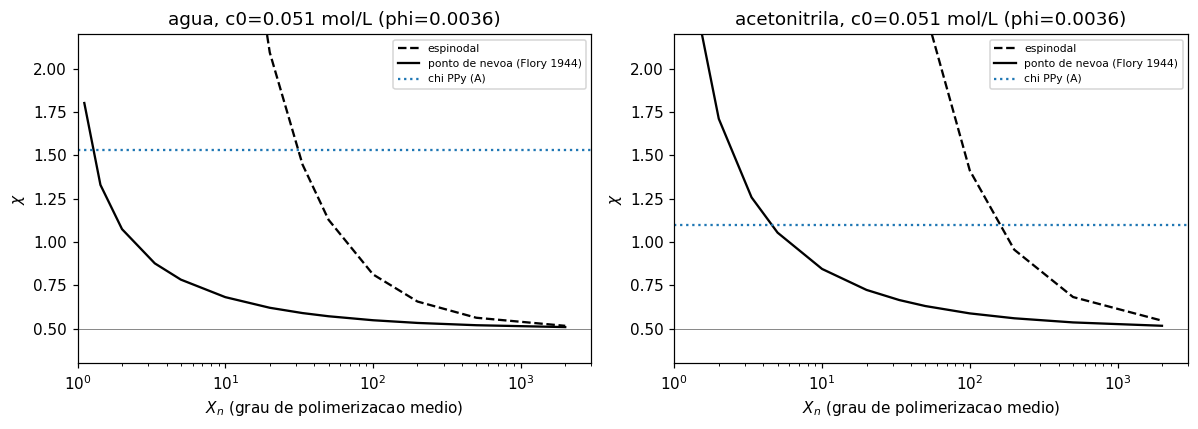

In [23]:
def cloud_chi(phi, p, r, nf=220):
# chi no ponto de nevoa (parental: phi, distribuicao de Flory com conversao p). Retorna (chi, phi_fase_incipiente)
    xmax = int(35/(1-p)); x = np.arange(1, xmax+1); N = r*x
    w = w_mass(x,p); w = w/w.sum()
    phi1 = phi*w; phi01 = 1-phi; S1 = np.sum(phi1/N) + phi01
    smax = -np.log(p)/r # sigma_max: a soma diverge alem disso
    def g(sig):
        e = -sig*N
        if e.max() > 600: return None
        phi2 = phi1*np.exp(e); phi02 = 1-phi2.sum()
        if phi02 <= 1e-9: return None
        S2 = np.sum(phi2/N) + phi02
        c1 = (S1-S2-sig)/(phi01**2-phi02**2)
        c2 = (S1-S2-np.log(phi01/phi02))/((1-phi01)**2-(1-phi02)**2)
        return c1-c2, c1, phi02
    prev = None
    fgrid = np.unique(np.concatenate([np.geomspace(0.01, 0.2, 50), np.linspace(0.2, 0.995, nf)]))
    for f in fgrid:
        sg = -smax*f; v = g(sg)
        if v is None: prev = None; continue
        if prev is not None and prev[1][0]*v[0] < 0:
            h = lambda s: g(s)[0]
            try: root = brentq(h, prev[0], sg)
            except Exception: return np.nan, np.nan
            gg = g(root); return gg[1], 1-gg[2]
        prev = (sg, v)
    return np.nan, np.nan

def p_critico_espinodal(phi, chi, r):
    d = 2*chi - 1/(1-phi)
    if d <= 0: return np.nan
    Nw_star = 1/(phi*d); Xw_star = Nw_star/r
    return (Xw_star-1)/(Xw_star+1) if Xw_star > 1 else 0.0

PGRID = np.array([0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.85,0.9,0.93,0.95,0.97,0.98,0.99,0.995,0.998,0.9995])

def p_critico_nevoa(phi, chi, r):
# chi_nevoa(p) diminui com p. Procura o p em que chi_nevoa(p) = chi.
    vals = np.array([cloud_chi(phi, q, r)[0] for q in PGRID])
    ok = np.isfinite(vals)
    if not ok.any(): return np.nan
    pg, vv = PGRID[ok], vals[ok]
    if vv[0] <= chi: return pg[0] # ja instavel na menor conversao avaliada
    if vv[-1] > chi: return np.inf # nao separa ate a maior conversao avaliada
    i = np.where((vv[:-1] > chi) & (vv[1:] <= chi))[0][0]
    f = lambda q: cloud_chi(phi, q, r)[0] - chi
    return brentq(f, pg[i], pg[i+1], xtol=1e-7)

# curvas chi(p) para o ponto de operacao de referencia
def curvas(solv, c0, ax):
    v = solventes[solv]; r = V_rep/v['V']; phi = c0*pirrol['V']/1000
    pp = np.array([0.1,0.3,0.5,0.7,0.8,0.9,0.95,0.97,0.98,0.99,0.995,0.998,0.9995])
    esp = [chi_spinodal(phi, r*Xw(q)) for q in pp]
    nev = [cloud_chi(phi,q,r)[0] for q in pp]
    xx = [Xn(q) for q in pp]
    ax.semilogx(xx, esp, 'k--', label='espinodal')
    ax.set_xlim(1, 3000)
    ax.semilogx(xx, nev, 'k-',  label='ponto de nevoa (Flory 1944)')
    for k,d in ppy_hansen.items():
        ax.axhline(chi_hansen(d, v, v['V'], alpha), ls=':', label=f'chi PPy ({k})')
    ax.axhline(0.5, color='gray', lw=0.6)
    ax.set_xlabel(r'$X_n$ (grau de polimerizacao medio)'); ax.set_ylabel(r'$\chi$')
    ax.set_title(f'{solv}, c0={c0:.3f} mol/L (phi={phi:.4f})'); ax.set_ylim(0.3, 2.2); ax.legend(fontsize=7)

fig,ax = plt.subplots(1,2,figsize=(11,4))
curvas('agua', c0_receita, ax[0]); curvas('acetonitrila', c0_receita, ax[1])
plt.tight_layout(); plt.show()

In [24]:
# tabela de sensibilidade
rows = []
for s_,v in solventes.items():
    r = V_rep/v['V']
    for k,d in ppy_hansen.items():
        chi = chi_hansen(d, v, v['V'], alpha)
        for c0 in c0_lista:
            phi = c0*pirrol['V']/1000
            pe = p_critico_espinodal(phi, chi, r)
            pn = p_critico_nevoa(phi, chi, r)
            obs = ''
            if np.isfinite(pn) and pn <= 0.2: obs = 'chi unico superestima o monomero (instabilidade)'
            if pn == np.inf: obs = 'sem separacao ate p=0,9995'
            def X(pv, f): return f(pv) if np.isfinite(pv) else np.nan
            rows.append(dict(solvente=s_, PPy=k, c0=c0, phi=round(phi,4), chi=round(chi,3),
                             p_espinodal=pe, Xn_espinodal=X(pe,Xn),
                             p_nevoa=pn, Xn_nevoa=X(pn,Xn), Xw_nevoa=X(pn,Xw), obs=obs))
sens = pd.DataFrame(rows)
display(sens.round(4))

,solvente,PPy,c0,phi,chi,p_espinodal,Xn_espinodal,p_nevoa,Xn_nevoa,Xw_nevoa,obs
0,acetonitrila,A,0.0257,0.0018,1.098,0.9967,304.4086,0.7870,4.6940,8.3880,
1,acetonitrila,A,0.0515,0.0036,1.098,0.9935,152.6825,0.7787,4.5180,8.0359,
2,acetonitrila,A,0.1030,0.0071,1.098,0.9870,76.8217,0.7681,4.3124,7.6248,
3,agua,A,0.0257,0.0018,1.533,0.9835,60.6907,0.2047,1.2573,1.5147,
4,agua,A,0.0515,0.0036,1.533,0.9673,30.6215,0.1916,1.2370,1.4740,chi unico superestima o monomero (instabilidade)
5,agua,A,0.1030,0.0071,1.533,0.9358,15.5871,0.1743,1.2111,1.4222,chi unico superestima o monomero (instabilidade)


Interpretação: p_nevoa é a conversão em que a mistura de oligômeros começa a se separar em duas fases; Xn_nevoa e Xw_nevoa são os comprimentos médios de cadeia nesse ponto. inf significa que não há separação até $p=0{,}9995$; um valor igual a 0,30 significa que a mistura já está instável no início da faixa varrida. Os $\delta_{PPy}$ vêm da Seção 1b.

### 5b. Suposição Monodispersividade

A tabela mistura duas coisas: polidispersidade e o fato de usarmos um $\chi$ único para o monômero. Para separar os efeitos, foi calculado, com a binodal binária de Flory-Huggins (Seção 5), a solubilidade $\phi_a(x)$ de um oligômero de $x$ unidades puro (monodisperso), e o comprimento $x^*$ a partir do qual $\phi_a(x)<\phi_0$ (ele excederia o limite de solubilidade na concentração de síntese). Se um comprimento $x$ é miscível em qualquer proporção, não há binodal ($\chi<\chi_c(N)$).

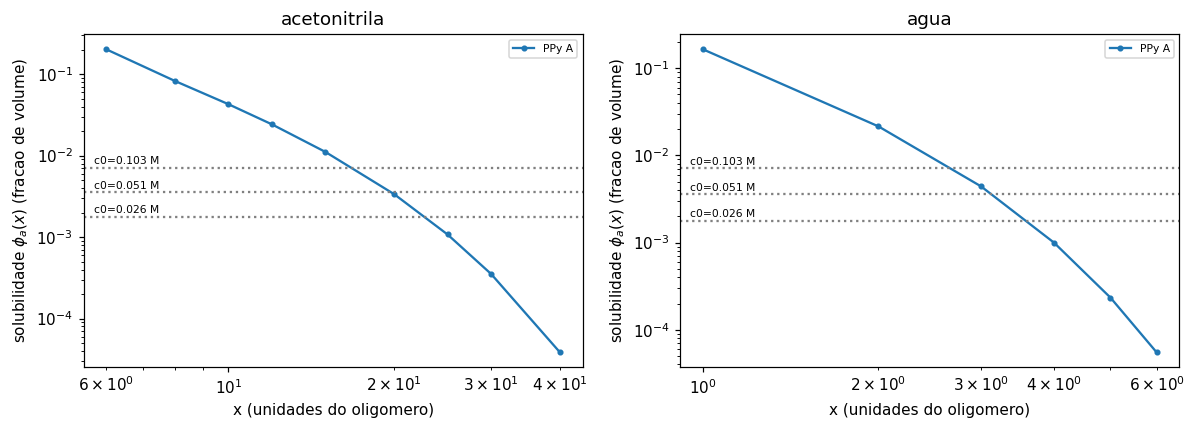

,c0,0.025742,0.051485,0.102970
solvente,PPy,,,
acetonitrila,A,22.7,19.7,16.7
agua,A,3.6,3.1,2.7


In [25]:
def solub_oligomero(x, chi, r):
    N = r*x
    if 0.5*(1+1/np.sqrt(N))**2 >= chi: return np.nan # miscivel em toda a faixa
    try:
        b = binodal_binaria(N, chi)
    except Exception:
        return np.nan
    return b[0] if b else np.nan

xs = np.array([1,2,3,4,5,6,8,10,12,15,20,25,30,40,50,60,80,100,150])
resultados = {}
for s_,v in solventes.items():
    r = V_rep/v['V']
    for k,d in ppy_hansen.items():
        chi = chi_hansen(d, v, v['V'], alpha)
        resultados[(s_,k)] = np.array([solub_oligomero(x, chi, r) for x in xs])

fig,ax = plt.subplots(1,2,figsize=(11,4))
for a_,s_ in zip(ax, solventes):
    for k in ppy_hansen:
        a_.loglog(xs, resultados[(s_,k)], 'o-', ms=3, label=f'PPy {k}')
    for c0 in c0_lista:
        a_.axhline(c0*pirrol['V']/1000, ls=':', color='gray')
        a_.text(0.02, c0*pirrol['V']/1000*1.1, f'c0={c0:.3f} M', fontsize=7, transform=a_.get_yaxis_transform())
    a_.set_xlabel('x (unidades do oligomero)'); a_.set_ylabel(r'solubilidade $\phi_a(x)$ (fracao de volume)')
    a_.set_title(s_); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()

# x*: primeiro comprimento em que a solubilidade cai abaixo de phi0 (interpolacao log-log; nan = miscivel / sem dado)
linhas = []
for (s_,k),sol in resultados.items():
    for c0 in c0_lista:
        phi0 = c0*pirrol['V']/1000
        ok = np.isfinite(sol)
        xstar = np.nan
        if ok.any():
            xx, ss = xs[ok], sol[ok]
            if ss[0] < phi0: xstar = xx[0]
            else:
                idx = np.where(ss < phi0)[0]
                if len(idx):
                    i = idx[0]
                    xstar = float(np.exp(np.interp(np.log(phi0), [np.log(ss[i]), np.log(ss[i-1])], [np.log(xx[i]), np.log(xx[i-1])])))
                else: xstar = np.inf
        linhas.append(dict(solvente=s_, PPy=k, c0=c0, x_estrela=xstar))
display(pd.DataFrame(linhas).pivot_table(index=['solvente','PPy'], columns='c0', values='x_estrela').round(1))

## Resumão para Joanny :)

In [26]:
ref = dict(solvente='agua', ppy='A', c0=c0_receita)
v = solventes[ref['solvente']]; r = V_rep/v['V']; phi = ref['c0']*pirrol['V']/1000
chi_ref = chi_hansen(ppy_hansen[ref['ppy']], v, v['V'], alpha)
p_star = p_critico_nevoa(phi, chi_ref, r)

def resumo(pv):
    return dict(p=float(pv), Xn=float(Xn(pv)), Xw=float(Xw(pv)), Xz=float(Xz(pv)), PDI=float(1+pv),
                N_sitios_Nw=float(r*Xw(pv)), monomero_residual_massa=float((1-pv)**2))

saida = dict(
    caso=ref, T_K=T, V_sitio_cm3_mol=v['V'], r_V_rep_sobre_Vs=float(r), phi_pirrol_inicial=float(phi),
    chi=float(chi_ref), v_sobre_v0=float(1-2*chi_ref),
    p_estrela_nevoa=float(p_star) if np.isfinite(p_star) else None,
    distribuicao_em_p_estrela=resumo(p_star) if np.isfinite(p_star) and p_star < 1 else None,
    varredura_p=[resumo(q) for q in [0.9,0.95,0.99,0.995,0.999]],
    aviso='Em agua a mistura separa em oligomeros muito curtos: o comprimento de cadeia a usar em Joanny NAO vem da termodinamica de mistura (vem da cinetica/caracterizacao). rho_PPy e deltas do PPy dependem de fonte.'
)
print(json.dumps({k:saida[k] for k in ['chi','v_sobre_v0','p_estrela_nevoa','distribuicao_em_p_estrela']}, indent=2, ensure_ascii=False))

{
  "chi": 1.5327809039107534,
  "v_sobre_v0": -2.065561807821507,
  "p_estrela_nevoa": 0.19158003557670428,
  "distribuicao_em_p_estrela": {
    "p": 0.19158003557670428,
    "Xn": 1.236980831755401,
    "Xw": 1.4739616635108022,
    "Xz": 1.8717206468437282,
    "PDI": 1.1915800355767043,
    "N_sitios_Nw": 3.330488029616856,
    "monomero_residual_massa": 0.6535428388781627
  }
}


### Referências 

1. Flory, P. J. *Molecular Size Distribution in Linear Condensation Polymers.* **J. Am. Chem. Soc.** 58, 1877–1885 (1936). — distribuição mais provável (Seções 2–3).
2. Huggins, M. L. *Solutions of Long Chain Compounds.* **J. Chem. Phys.** 9, 440 (1941); Flory, P. J. *Thermodynamics of High Polymer Solutions.* **J. Chem. Phys.** 10, 51–61 (1942). — energia livre de mistura (Seção 4).
3. Flory, P. J. *Thermodynamics of Heterogeneous Polymers and Their Solutions.* **J. Chem. Phys.** 12, 425–438 (1944). — polímeros polidispersos, equilíbrio de fases e fracionamento (Seções 4 e 6).
4. Flory, P. J. *Principles of Polymer Chemistry.* Cornell Univ. Press, 1953 (cap. III, distribuição de tamanhos; cap. XII, soluções de polímeros). *Confira a numeração dos capítulos na sua edição.*
5. Flory, P. J. *Phase equilibria in solutions of rod-like particles.* **Proc. R. Soc. A** 234, 73–89 (1956); e *Statistical thermodynamics of semi-flexible chain molecules.* **Proc. R. Soc. A** 234, 60–73 (1956). — cadeias rígidas (limitação, abaixo).
6. Scott, R. L.; Magat, M. *The Thermodynamics of High-Polymer Solutions. I.* **J. Chem. Phys.** 13, 172 (1945) — misturas polidispersas.
7. Lindvig, T.; Michelsen, M. L.; Kontogeorgis, G. M. *Fluid Phase Equilib.* 203, 247–260 (2002) — $\chi$ a partir de Hansen.
8. Hansen, C. M. *Hansen Solubility Parameters: A User's Handbook*, 2ª ed., CRC Press, 2007.
9. Emerson, J. A. et al. *Macromolecules* 46, 6533–6540 (2013) — roteiro de $\chi$ para polímero conjugado (P3HT).
10. Sadki, S.; Schottland, P.; Brodie, N.; Sabouraud, G. *The mechanisms of pyrrole electropolymerization.* **Chem. Soc. Rev.** 29, 283–293 (2000).
11. John, R.; Wallace, G. G. *J. Electroanal. Chem.* 306, 157–167 (1991) — crescimento do PPy por precipitação contínua de oligômeros solúveis.
12. Heinze, J.; Frontana-Uribe, B. A.; Ludwigs, S. *Chem. Rev.* 110, 4724–4771 (2010)